In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install tensorflow

In [3]:
import os, glob, json, random, itertools, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import top_k_accuracy_score
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TF version:", tf.__version__)

TF version: 2.21.0


In [4]:
DRIVE_DATASET_PATH = '/content/drive/MyDrive/dataset_batik_fix'
SEED = 123
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

In [12]:
root = DRIVE_DATASET_PATH

def try_candidates():
  pd = os.path.join(root, "processed_dataset")
  if all(os.path.isdir(os.path.join(pd, x)) for x in ["train_original", "val", "test"]):
    return pd
  return None

def search_processed_dataset(root=root):
  for pd in glob.glob(os.path.join(root, "**/processed_dataset"), recursive=True):
    if all(os.path.isdir(os.path.join(pd, x)) for x in ["train_original", "val", "test"]):
      return pd
  return None

In [13]:
DATA_DIR = try_candidates() or search_processed_dataset()
if DATA_DIR is None:
    raise FileNotFoundError(
        "Tidak ditemukan 'processed_dataset' dengan subfolder train/val/test di /kaggle/input. "
        "Klik Add Data → pilih dataset Anda."
    )

TRAIN_DIR = os.path.join(DATA_DIR, "train_original")
VAL_DIR   = os.path.join(DATA_DIR, "val")
TEST_DIR  = os.path.join(DATA_DIR, "test")
print("DATA_DIR:", DATA_DIR)


DATA_DIR: /content/drive/MyDrive/dataset_batik_fix/processed_dataset


In [14]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, label_mode='categorical', image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=True, seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, label_mode='categorical', image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, label_mode='categorical', image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Found 2101 files belonging to 20 classes.
Found 600 files belonging to 20 classes.
Found 300 files belonging to 20 classes.
['batik_betawi', 'batik_bokor_kencono', 'batik_buketan', 'batik_dayak', 'batik_jlamprang', 'batik_kawung', 'batik_liong', 'batik_mega_mendung', 'batik_parang', 'batik_sekarjagad', 'batik_sidoluhur', 'batik_sidomukti', 'batik_sidomulyo', 'batik_singa_barong', 'batik_srikaton', 'batik_tribusono', 'batik_tujuh_rupa', 'batik_tuntrum', 'batik_wahyu_tumurun', 'batik_wirasat']


In [15]:
def count_per_class(root):
  rows = []
  for cls in sorted(next(os.walk(root))[1]):
    n = len(glob.glob(os.path.join(root, cls, "*")))
    rows.append((cls, n))
  return pd.DataFrame(rows, columns=["class","count"])

df_train = count_per_class(TRAIN_DIR)
df_val   = count_per_class(VAL_DIR)
df_test  = count_per_class(TEST_DIR)

summary = (df_train.set_index("class")
           .join(df_val.set_index("class"), lsuffix="_train", rsuffix="_val")
           .join(df_test.set_index("class"), rsuffix="_test")
           .rename(columns={"count":"count_test"})
           .reset_index())
summary["total"] = summary["count_train"] + summary["count_val"] + summary["count_test"]
summary = summary.sort_values("class")
summary.style.background_gradient(cmap="Blues").format(precision=0)


,class,count_train,count_val,count_test,total
0,batik_betawi,105,30,15,150
1,batik_bokor_kencono,105,30,15,150
2,batik_buketan,105,30,15,150
3,batik_dayak,105,30,15,150
4,batik_jlamprang,105,30,15,150
5,batik_kawung,105,30,15,150
6,batik_liong,105,30,15,150
7,batik_mega_mendung,105,30,15,150
8,batik_parang,105,30,15,150
9,batik_sekarjagad,105,30,15,150


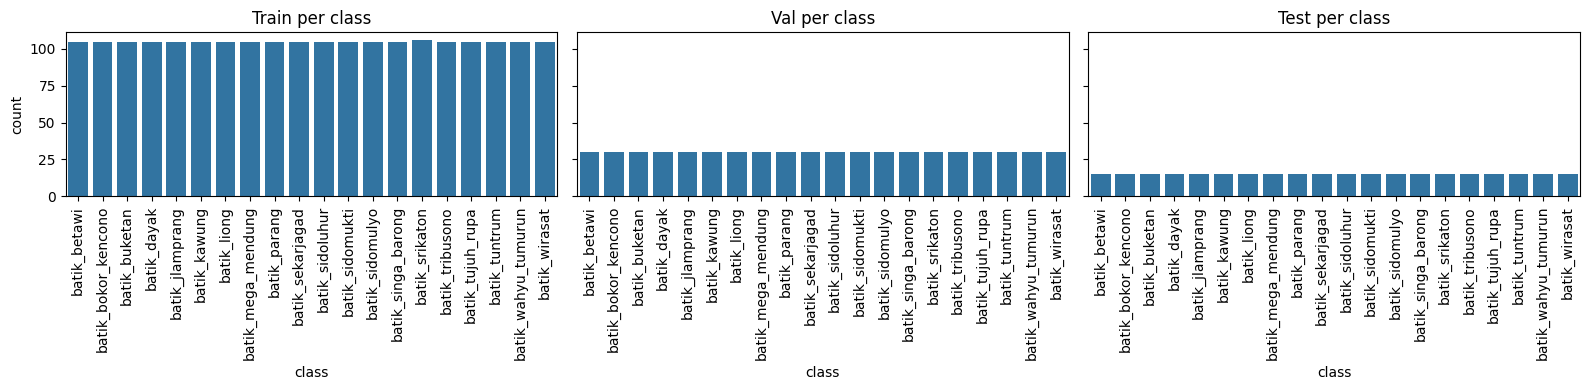

In [16]:
fig, axes = plt.subplots(1,3, figsize=(16,4), sharey=True)
sns.barplot(data=df_train.sort_values("class"), x="class", y="count", ax=axes[0])
axes[0].set_title("Train per class"); axes[0].tick_params(axis='x', rotation=90)
sns.barplot(data=df_val.sort_values("class"),   x="class", y="count", ax=axes[1])
axes[1].set_title("Val per class"); axes[1].tick_params(axis='x', rotation=90)
sns.barplot(data=df_test.sort_values("class"),  x="class", y="count", ax=axes[2])
axes[2].set_title("Test per class"); axes[2].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

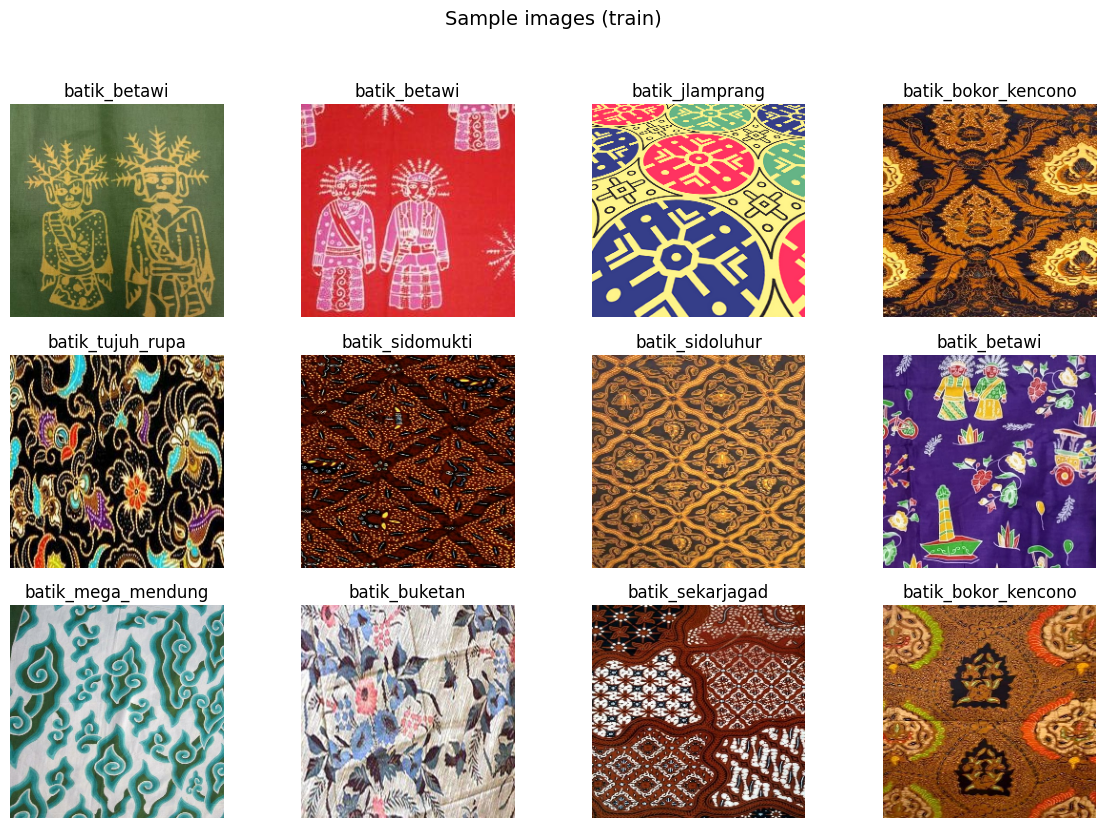

In [17]:
def show_samples(ds, n=12, title="Sample images (train)"):
  images, labels = next(iter(ds))
  idx = np.random.choice(range(images.shape[0]), size=min(n, images.shape[0]), replace=False)
  plt.figure(figsize=(12,8))
  for i,k in enumerate(idx):
    ax = plt.subplot(3, 4, i+1)
    plt.imshow(images[k].numpy().astype("uint8"))
    plt.title(class_names[np.argmax(labels[k].numpy())])
    plt.axis("off")
  plt.suptitle(title, fontsize=14, y=1.03)
  plt.tight_layout(); plt.show()

show_samples(train_ds, n=12, title="Sample images (train)")

# b

In [19]:
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

base_model = MobileNetV2(input_shape=IMG_SIZE+(3,), include_top=False, weights="imagenet")
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [20]:
inputs = keras.Input(shape=IMG_SIZE+(3,))
x = data_augmentation(inputs)
x = layers.Lambda(preprocess_input, name="mobilenetv2_preproc")(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)  # dtype for mixed precision safety

model = keras.Model(inputs, outputs, name="batik_mobilenetv2")

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.summary()


Model: "batik_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preproc (Lambda)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,283,604 (8.71 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [21]:
ckpt1 = "checkpoints/mnv2_stage1.keras"
os.makedirs(os.path.dirname(ckpt1), exist_ok=True)

callbacks1 = [
    keras.callbacks.ModelCheckpoint(ckpt1, monitor="val_accuracy", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)
]

history1 = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=callbacks1)

Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 242s 4s/step - accuracy: 0.5093 - loss: 1.7420 - val_accuracy: 0.7983 - val_loss: 0.8180
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 176s 2s/step - accuracy: 0.8610 - loss: 0.5742 - val_accuracy: 0.8400 - val_loss: 0.5674
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.9077 - loss: 0.3715 - val_accuracy: 0.8867 - val_loss: 0.4404
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 160s 2s/step - accuracy: 0.9315 - loss: 0.2873 - val_accuracy: 0.9117 - val_loss: 0.3786
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 209s 3s/step - accuracy: 0.9400 - loss: 0.2320 - val_accuracy: 0.9067 - val_loss: 0.3419
Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - accuracy: 0.9529 - loss: 0.1910 - val_accuracy: 0.9217 - val_loss: 0.3182
Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 222s 3s/step - accuracy: 0.9672 - loss: 0.1547 - val_accuracy: 0.9317 - val_loss: 0.2853
Epoch 8/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 167s 3s/step - accuracy: 0.9719 - loss: 0.1375 - val_accuracy: 0.9200 - v

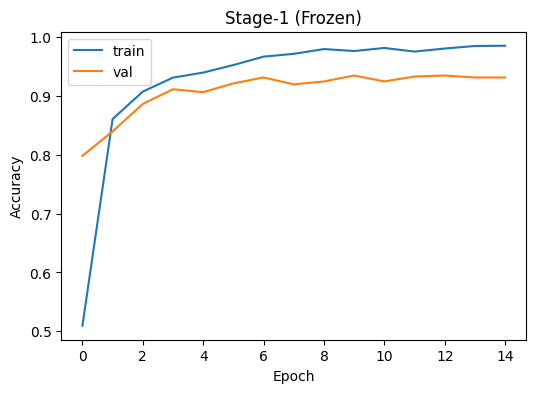

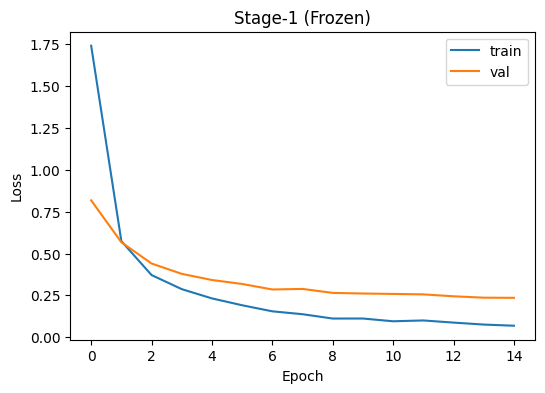

In [22]:
def plot_hist(h, title):
    plt.figure(figsize=(6,4))
    plt.plot(h.history["accuracy"], label="train")
    plt.plot(h.history["val_accuracy"], label="val")
    plt.ylabel("Accuracy"); plt.xlabel("Epoch"); plt.title(title); plt.legend(); plt.show()

    plt.figure(figsize=(6,4))
    plt.plot(h.history["loss"], label="train")
    plt.plot(h.history["val_loss"], label="val")
    plt.ylabel("Loss"); plt.xlabel("Epoch"); plt.title(title); plt.legend(); plt.show()

plot_hist(history1, "Stage-1 (Frozen)")

Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 191s 3s/step - accuracy: 0.8724 - loss: 0.4437 - val_accuracy: 0.9033 - val_loss: 0.3018 - learning_rate: 1.0000e-04
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 215s 3s/step - accuracy: 0.9538 - loss: 0.1535 - val_accuracy: 0.9100 - val_loss: 0.2940 - learning_rate: 1.0000e-04
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 199s 3s/step - accuracy: 0.9795 - loss: 0.0874 - val_accuracy: 0.9050 - val_loss: 0.2781 - learning_rate: 1.0000e-04
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 189s 3s/step - accuracy: 0.9876 - loss: 0.0518 - val_accuracy: 0.9133 - val_loss: 0.2730 - learning_rate: 1.0000e-04
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 201s 3s/step - accuracy: 0.9938 - loss: 0.0373 - val_accuracy: 0.9233 - val_loss: 0.2660 - learning_rate: 1.0000e-04
Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 203s 3s/step - accuracy: 0.9962 - loss: 0.0270 - val_accuracy: 0.9250 - val_loss: 0.2529 - learning_rate: 1.0000e-04
Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 201s 3s/step - accuracy: 0.9976 

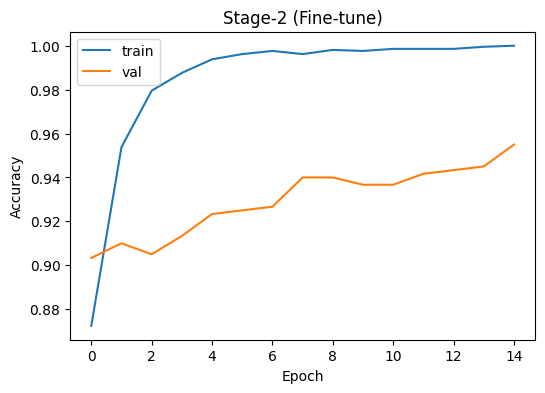

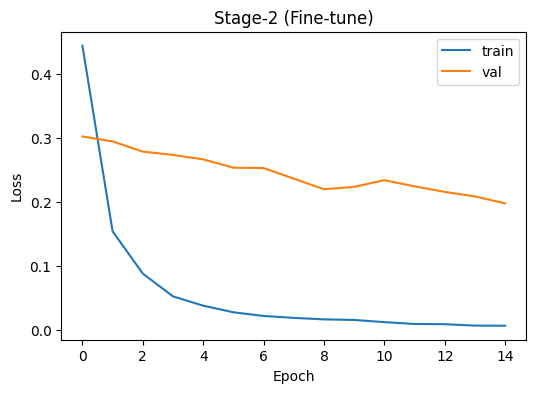

In [23]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

ckpt2 = "checkpoints/mnv2_stage2.keras"
callbacks2 = [
    keras.callbacks.ModelCheckpoint(ckpt2, monitor="val_accuracy", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1)
]

history2 = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=callbacks2)
plot_hist(history2, "Stage-2 (Fine-tune)")

# c

In [24]:
vt_ds = val_ds.concatenate(test_ds)

y_true, y_prob = [], []
for xb, yb in vt_ds:
    pb = model.predict(xb, verbose=0)
    y_prob.append(pb)
    y_true.append(np.argmax(yb.numpy(), axis=1))

y_prob = np.concatenate(y_prob, axis=0)
y_true = np.concatenate(y_true, axis=0)
y_pred = y_prob.argmax(axis=1)

In [25]:
support = np.bincount(y_true, minlength=len(class_names))
print("Support per class (val+test):")
for cls, s in zip(class_names, support):
    print(f"- {cls}: {int(s)}")

print("\n[CLASSIFICATION REPORT] (val + test)")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Support per class (val+test):
- batik_betawi: 45
- batik_bokor_kencono: 45
- batik_buketan: 45
- batik_dayak: 45
- batik_jlamprang: 45
- batik_kawung: 45
- batik_liong: 45
- batik_mega_mendung: 45
- batik_parang: 45
- batik_sekarjagad: 45
- batik_sidoluhur: 45
- batik_sidomukti: 45
- batik_sidomulyo: 45
- batik_singa_barong: 45
- batik_srikaton: 45
- batik_tribusono: 45
- batik_tujuh_rupa: 45
- batik_tuntrum: 45
- batik_wahyu_tumurun: 45
- batik_wirasat: 45

[CLASSIFICATION REPORT] (val + test)
                     precision    recall  f1-score   support

       batik_betawi     0.9565    0.9778    0.9670        45
batik_bokor_kencono     0.9783    1.0000    0.9890        45
      batik_buketan     0.9574    1.0000    0.9783        45
        batik_dayak     0.9545    0.9333    0.9438        45
    batik_jlamprang     0.8696    0.8889    0.8791        45
       batik_kawung     0.9130    0.9333    0.9231        45
        batik_liong     1.0000    1.0000    1.0000        45
 batik_mega

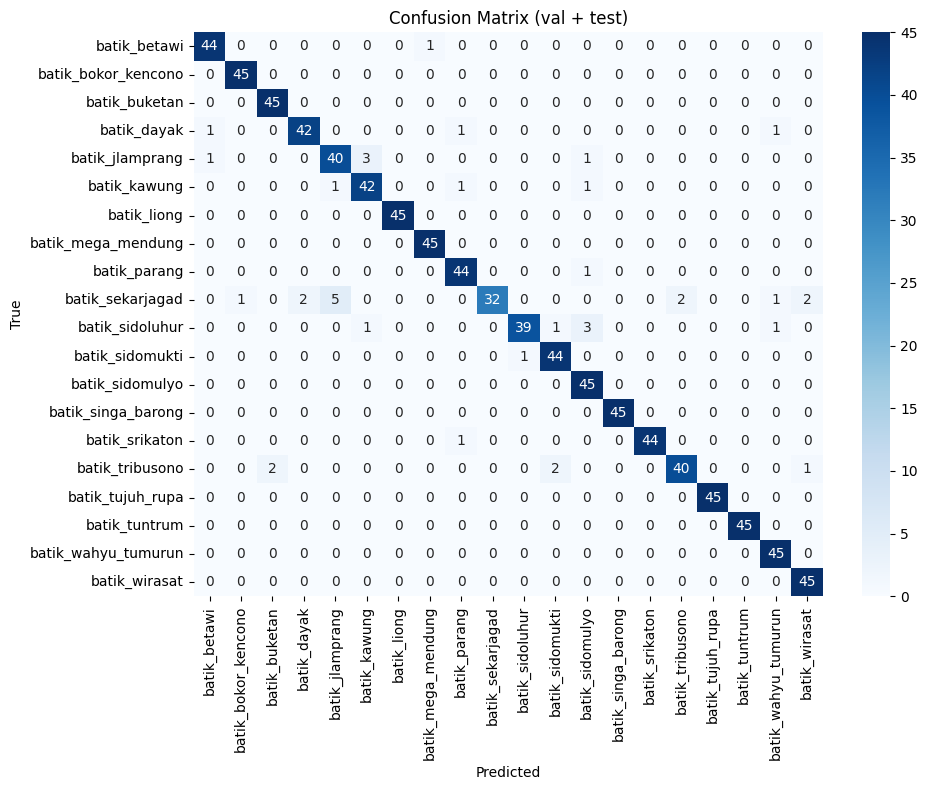

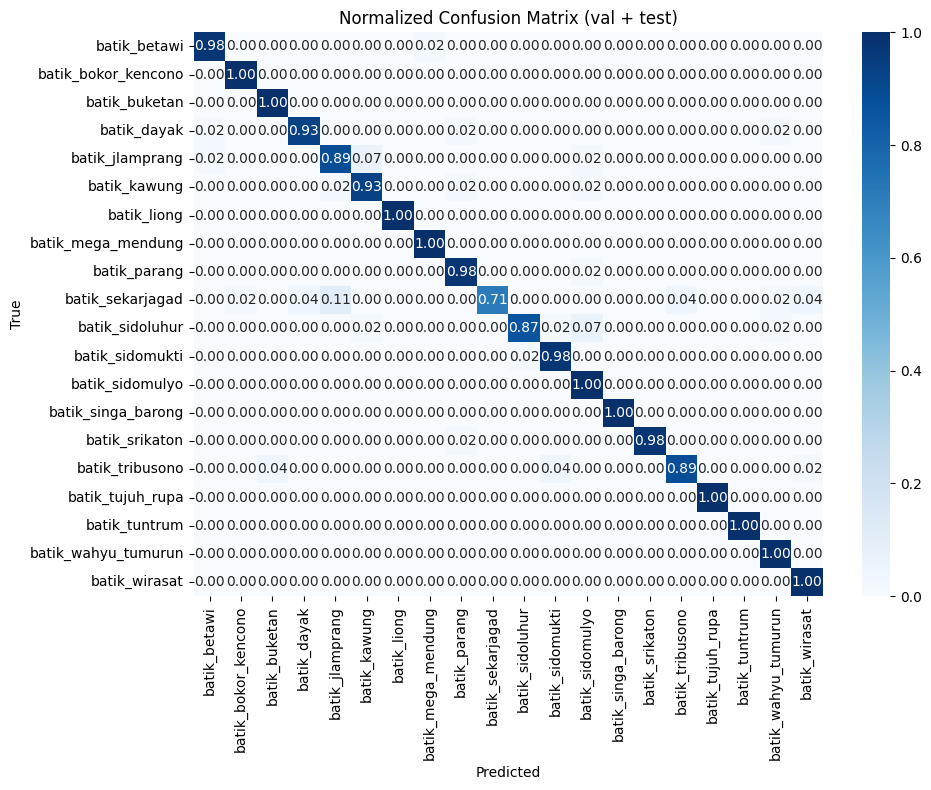

In [26]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix (val + test)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10,8))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Normalized Confusion Matrix (val + test)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

In [27]:
ckpt_path = "checkpoints/mobilenetv2_stage1.keras"
os.makedirs(os.path.dirname(ckpt_path), exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(ckpt_path, monitor='val_accuracy', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
]

history1 = model.fit(
    train_ds,
    epochs=15,
    validation_data=val_ds,
    callbacks=callbacks
)


Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 181s 3s/step - accuracy: 1.0000 - loss: 0.0040 - val_accuracy: 0.9533 - val_loss: 0.1937
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 198s 3s/step - accuracy: 0.9995 - loss: 0.0055 - val_accuracy: 0.9533 - val_loss: 0.1894
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 190s 3s/step - accuracy: 0.9995 - loss: 0.0053 - val_accuracy: 0.9517 - val_loss: 0.1852
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 209s 3s/step - accuracy: 0.9995 - loss: 0.0043 - val_accuracy: 0.9517 - val_loss: 0.1840
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 181s 3s/step - accuracy: 1.0000 - loss: 0.0037 - val_accuracy: 0.9533 - val_loss: 0.1885
Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 174s 3s/step - accuracy: 0.9995 - loss: 0.0045 - val_accuracy: 0.9533 - val_loss: 0.1879


Misclassified: 39


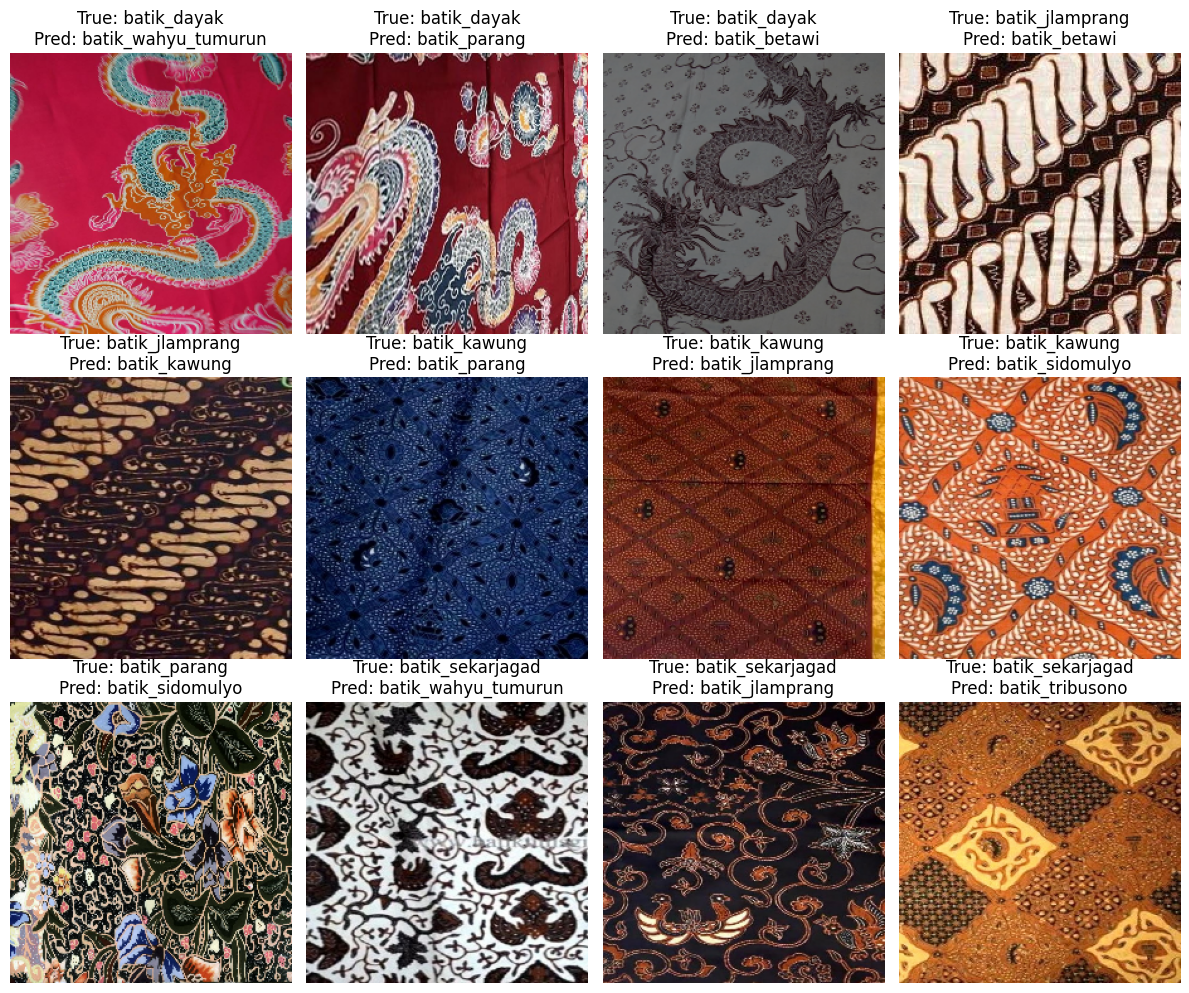

In [28]:
imgs = []
for xb, _ in test_ds:
    imgs.extend(xb.numpy().astype("uint8"))
imgs = np.array(imgs)

mis_idx = np.where(y_true != y_pred)[0]
print("Misclassified:", len(mis_idx))

n_show = min(12, len(mis_idx))
plt.figure(figsize=(12,10))
for i, idx in enumerate(mis_idx[:n_show]):
    ax = plt.subplot(3, 4, i+1)
    plt.imshow(imgs[idx])
    plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


Path: /content/drive/MyDrive/dataset_batik_fix/processed_dataset/test/batik_tribusono/-30-_jpg.rf.3f2f3015da5331efd850a1d5033af931.jpg | True class: batik_tribusono


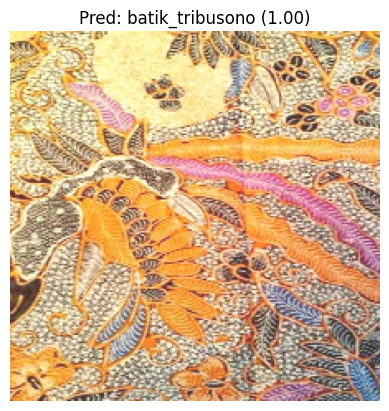

Prediksi: batik_tribusono
Top-5: ['batik_tribusono(1.00)', 'batik_liong(0.00)', 'batik_singa_barong(0.00)', 'batik_buketan(0.00)', 'batik_dayak(0.00)']


In [29]:
def predict_image(img_path, model, class_names, use_model_preproc=True, topk=5, show=True):
    img = image.load_img(img_path, target_size=IMG_SIZE)
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    if not use_model_preproc:
        x = preprocess_input(x)
    p = model.predict(x, verbose=0)[0]
    idx = p.argsort()[-topk:][::-1]
    top = [(class_names[i], float(p[i])) for i in idx]
    if show:
        plt.imshow(img); plt.axis("off")
        plt.title(f"Pred: {top[0][0]} ({top[0][1]:.2f})"); plt.show()
    return top[0][0], top

some_cls = random.choice(class_names)
cls_dir = os.path.join(TEST_DIR, some_cls)
img_path = os.path.join(cls_dir, random.choice(os.listdir(cls_dir)))
print("Path:", img_path, "| True class:", some_cls)

pred, topk = predict_image(img_path, model, class_names, use_model_preproc=True, topk=5, show=True)
print("Prediksi:", pred)
print("Top-5:", [f"{n}({p:.2f})" for n,p in topk])

In [31]:
tflite_model_path = '/content/batik_mobilenetv2.tflite'
if not os.path.exists(tflite_model_path):
  print("Mengonversi model ke format TFLite...")
  converter = tf.lite.TFLiteConverter.from_keras_model(model)
  tflite_model = converter.convert()
  with open(tflite_model_path, 'wb') as f:
    f.write(tflite_model)
  print("Model berhasil dikonversi dan disimpan di:", tflite_model_path)

interpreter = tf.lite.Interpreter(model_path=tflite_model_path)
interpreter.allocate_tensors()
inp = interpreter.get_input_details()
out = interpreter.get_output_details()

for images, labels in test_ds.take(1):
  img = images[0:1].numpy()
  interpreter.set_tensor(inp[0]['index'], img)
  interpreter.invoke()
  pred = interpreter.get_tensor(out[0]['index'])
  print("Prediksi :", class_names[np.argmax(pred)])
  print("Asli :", class_names[np.argmax(labels[0].numpy())])

Mengonversi model ke format TFLite...
Saved artifact at '/tmp/tmpw05vpuur'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 20), dtype=tf.float32, name=None)
Captures:
  132292583936208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132292584179280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132292583936016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132292583936400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132292583936976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132292584179664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132292583941008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132292583943504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132292588338448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132292588323472: TensorSpec(shape=(), dty

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [32]:
from google.colab import files
files.download('/content/batik_mobilenetv2.tflite')
files.download('/content/labels.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FileNotFoundError: Cannot find file: /content/labels.txt